# Does large-scale background state (ENSO, PDO, MJO) predict ridging/warm-episode duration?

**Motivation.** Every upstream-mechanism notebook so far (`CA_2026_upstream_mechanism_composite.ipynb`,
`CA_ridging_persistence_drivers_upstream.ipynb`, `CA_ridging_persistence_drivers_waf.ipynb`)
tests an *instantaneous precursor or contemporaneous* field -- what the Pacific looked
like just before or during a given episode. None test *background conditions* -- the
slower-varying large-scale state the episode happens to occur within. Davis's own
analysis flags one specific background-state observation for March 2026: "an inactive
MJO." That is a single-case, qualitative claim, never tested statistically against
this project's own 47-48-event record, and two other standard background-state
indices -- ENSO (ONI) and the PDO -- have never been brought in at all.

This notebook fetches all three (`get_mjo_enso_pdo_indices.py` -- the first
non-ERA5-reanalysis, non-station data this project has used) and tests them against
event duration across the full 1990-2025 record, then locates the four WY2026
episodes, including March, within that distribution -- the same pattern as the two
upstream-precursor notebooks before it, applied to a genuinely different hypothesis
class (background favorability, not instantaneous precursor state).

**Real data-coverage caveats, stated up front:**
1. **PDO has no 2026 data at all** (NOAA PSL's PDO series currently ends August 2025).
   The fit-period (1990-2025) duration-vs-PDO test is unaffected, but March 2026 and
   its WY2026 siblings cannot be located within the PDO distribution -- that step is
   skipped for PDO specifically, not silently worked around.
2. **OMI (the MJO index used here) starts January 1991**, one year after this
   project's 1990 fit-period floor -- the handful of 1990 events get a missing MJO
   predictor rather than a wrong one, same convention as every other partial-coverage
   case in this project (e.g. the Jan-1 precursor-window clipping in
   `CA_ridging_persistence_drivers_upstream.ipynb`).
3. **ONI and the PDO are monthly; OMI is daily.** Monthly values are broadcast to
   every day of their month, then each event gets a day-weighted mean over its own
   actual window -- the same window-mean convention used throughout this project,
   not a new one invented for this notebook.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from scipy.stats import spearmanr, mannwhitneyu, percentileofscore
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
FIT_YEARS = list(range(1990, 2026))
THRESHOLD_SD = 1
VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]
COLOR = {'500 hPa height (ridging)': '#2a78d6', '700 hPa temperature (warm)': '#eb6834'}
N_BOOT = 2000
rng = np.random.default_rng(42)

MJO_ACTIVE_THRESH = 1.0   # standard literature amplitude threshold (WH04-style convention)

# Z500 episode-detection constants, identical to the prior upstream notebooks --
# needed in Section 5 to relocate the WY2026 episodes.
CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1


## 1. Load the full-record Method A event table

Same `ca_z500_t700_events_1990-2025_detrended_mindur5.csv` used by every notebook in
this mechanism thread.

In [2]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[events.threshold_sd == THRESHOLD_SD].reset_index(drop=True)

print(f'{len(events)} events at >= {THRESHOLD_SD} sigma, by variable:')
print(events.groupby('variable').size())
events[['variable', 'start_date', 'end_date', 'duration_days']].head(5)


95 events at >= 1 sigma, by variable:
variable
500 hPa height (ridging)      48
700 hPa temperature (warm)    47
dtype: int64


,variable,start_date,end_date,duration_days
0,500 hPa height (ridging),1990-02-21,1990-02-25,5
1,500 hPa height (ridging),1990-03-19,1990-03-23,5
2,500 hPa height (ridging),1990-04-10,1990-04-15,6
3,500 hPa height (ridging),1992-02-21,1992-02-28,8
4,500 hPa height (ridging),1992-04-24,1992-04-29,6


## 2. Load the three background-state indices

`get_mjo_enso_pdo_indices.py` already fetched these to `DATA_DIR`. ONI/PDO are
expanded from monthly to daily (broadcast within each month) so every event can get a
day-weighted mean over its own window, same convention as every daily predictor
elsewhere in this project.

In [3]:
oni = pd.read_csv(DATA_DIR / 'oni_index.csv')
pdo = pd.read_csv(DATA_DIR / 'pdo_index.csv')
omi = pd.read_csv(DATA_DIR / 'omi_index.csv', parse_dates=['date'])

all_days = pd.date_range('1990-01-01', '2026-12-31', freq='D')
day_ym = pd.DataFrame({'date': all_days, 'year': all_days.year, 'month': all_days.month})
oni_daily = day_ym.merge(oni, on=['year', 'month'], how='left').set_index('date')['oni']
pdo_daily = day_ym.merge(pdo, on=['year', 'month'], how='left').set_index('date')['pdo']
mjo_amp_daily = omi.set_index('date')['amplitude'].reindex(all_days)

print(f'ONI: {oni_daily.notna().sum()} of {len(oni_daily)} days have a value '
      f'({oni_daily.index[oni_daily.notna()].min().date()} to {oni_daily.index[oni_daily.notna()].max().date()})')
print(f'PDO: {pdo_daily.notna().sum()} of {len(pdo_daily)} days have a value '
      f'({pdo_daily.index[pdo_daily.notna()].min().date()} to {pdo_daily.index[pdo_daily.notna()].max().date()})')
print(f'OMI amplitude: {mjo_amp_daily.notna().sum()} of {len(mjo_amp_daily)} days have a value '
      f'({mjo_amp_daily.index[mjo_amp_daily.notna()].min().date()} to {mjo_amp_daily.index[mjo_amp_daily.notna()].max().date()})')


ONI: 13392 of 13514 days have a value (1990-01-01 to 2026-08-31)
PDO: 13027 of 13514 days have a value (1990-01-01 to 2025-08-31)
OMI amplitude: 12959 of 13514 days have a value (1991-01-01 to 2026-06-24)


## 3. Compute the three background-state predictors for every fit-period event

- `enso_oni`: day-weighted mean ONI over the event's own window
- `pdo_index`: day-weighted mean PDO over the event's own window
- `mjo_amplitude_mean`: day-weighted mean OMI amplitude over the event's own window
- `mjo_frac_active`: fraction of the event's own days with OMI amplitude >= 1.0

In [4]:
def window_mean(series, start, end):
    window = series.loc[str(start):str(end)]
    return float(window.mean()) if window.notna().any() else np.nan


def window_frac_active(series, start, end, thresh=MJO_ACTIVE_THRESH):
    window = series.loc[str(start):str(end)]
    valid = window.dropna()
    return float((valid >= thresh).mean()) if len(valid) else np.nan


rows = []
for row in events.itertuples():
    rows.append({
        'enso_oni': window_mean(oni_daily, row.start_date, row.end_date),
        'pdo_index': window_mean(pdo_daily, row.start_date, row.end_date),
        'mjo_amplitude_mean': window_mean(mjo_amp_daily, row.start_date, row.end_date),
        'mjo_frac_active': window_frac_active(mjo_amp_daily, row.start_date, row.end_date),
    })
bg_predictors = pd.DataFrame(rows)
events_full = pd.concat([events.reset_index(drop=True), bg_predictors], axis=1)
n_missing_mjo = events_full.mjo_amplitude_mean.isna().sum()
print(f'{n_missing_mjo} of {len(events_full)} events have no MJO predictor (pre-1991 OMI floor)')
events_full[['variable', 'start_date', 'duration_days'] + list(bg_predictors.columns)].head(5)


5 of 95 events have no MJO predictor (pre-1991 OMI floor)


,variable,start_date,duration_days,enso_oni,pdo_index,mjo_amplitude_mean,mjo_frac_active
0,500 hPa height (ridging),1990-02-21,5,0.19,-0.65,NaN,NaN
1,500 hPa height (ridging),1990-03-19,5,0.30,-0.62,NaN,NaN
2,500 hPa height (ridging),1990-04-10,6,0.27,0.27,NaN,NaN
3,500 hPa height (ridging),1992-02-21,8,1.50,0.31,1.564869,1.000000
4,500 hPa height (ridging),1992-04-24,6,1.30,0.75,1.036287,0.666667


## 4. Duration vs. each background-state predictor, full record

Spearman (primary) with a bootstrap CI for the three continuous predictors, same
convention as every other predictor-vs-duration test in this project. Separately, a
Mann-Whitney test contrasting duration for MJO-active-onset vs. MJO-inactive-onset
events (amplitude >= 1.0 for a majority of the event's own days) -- the literature's
standard active/inactive cut, and the direct generalization of Davis's specific
"inactive MJO" observation about March 2026.

In [5]:
def bootstrap_spearman_ci(x, y, n_boot=N_BOOT, ci=90, rng=rng):
    n = len(x)
    boot = np.empty(n_boot)
    idx_pool = np.arange(n)
    for b in range(n_boot):
        idx = rng.choice(idx_pool, size=n, replace=True)
        boot[b] = spearmanr(x[idx], y[idx]).statistic
    lo, hi = np.percentile(boot, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return lo, hi


PREDICTORS = ['enso_oni', 'pdo_index', 'mjo_amplitude_mean']
PRED_LABELS = {
    'enso_oni': 'ENSO (ONI, event-mean)',
    'pdo_index': 'PDO index (event-mean)',
    'mjo_amplitude_mean': 'MJO (OMI) amplitude, event-mean',
}

results = []
for col, label in VARS:
    sub = events_full[events_full.variable == label]
    for pred in PREDICTORS:
        valid = sub[['duration_days', pred]].dropna()
        x, y = valid.duration_days.values, valid[pred].values
        if len(valid) < 8:
            results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                             'rho': np.nan, 'p_spearman': np.nan, 'ci_lo': np.nan, 'ci_hi': np.nan})
            continue
        rho, p = spearmanr(x, y)
        lo, hi = bootstrap_spearman_ci(x, y)
        results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                         'rho': rho, 'p_spearman': p, 'ci_lo': lo, 'ci_hi': hi})

results_df = pd.DataFrame(results)
results_df['predictor_label'] = results_df.predictor.map(PRED_LABELS)
pd.set_option('display.width', 120)
print(results_df[['variable', 'predictor_label', 'n', 'rho', 'p_spearman', 'ci_lo', 'ci_hi']])

print('\nMJO active-onset vs. inactive-onset events (amplitude >= 1.0 for >=50% of event days):')
mw_rows = []
for col, label in VARS:
    sub = events_full[events_full.variable == label].dropna(subset=['mjo_frac_active'])
    active = sub[sub.mjo_frac_active >= 0.5].duration_days
    inactive = sub[sub.mjo_frac_active < 0.5].duration_days
    if len(active) >= 4 and len(inactive) >= 4:
        stat, p_mw = mannwhitneyu(active, inactive, alternative='two-sided')
    else:
        stat, p_mw = np.nan, np.nan
    mw_rows.append({'variable': label, 'n_active': len(active), 'n_inactive': len(inactive),
                     'median_duration_active': active.median(), 'median_duration_inactive': inactive.median(),
                     'U': stat, 'p_mannwhitney': p_mw})
mw_df = pd.DataFrame(mw_rows)
print(mw_df.to_string(index=False))


                     variable                  predictor_label   n       rho  p_spearman     ci_lo     ci_hi
0    500 hPa height (ridging)           ENSO (ONI, event-mean)  48  0.340987    0.017706  0.108055  0.543113
1    500 hPa height (ridging)           PDO index (event-mean)  48  0.463063    0.000919  0.218294  0.674469
2    500 hPa height (ridging)  MJO (OMI) amplitude, event-mean  45 -0.150465    0.323848 -0.380529  0.102286
3  700 hPa temperature (warm)           ENSO (ONI, event-mean)  47  0.072293    0.629167 -0.185862  0.328341
4  700 hPa temperature (warm)           PDO index (event-mean)  47  0.173876    0.242459 -0.089053  0.405610
5  700 hPa temperature (warm)  MJO (OMI) amplitude, event-mean  45 -0.072879    0.634243 -0.332083  0.197284

MJO active-onset vs. inactive-onset events (amplitude >= 1.0 for >=50% of event days):
                  variable  n_active  n_inactive  median_duration_active  median_duration_inactive     U  p_mannwhitney
  500 hPa height (ridging)   

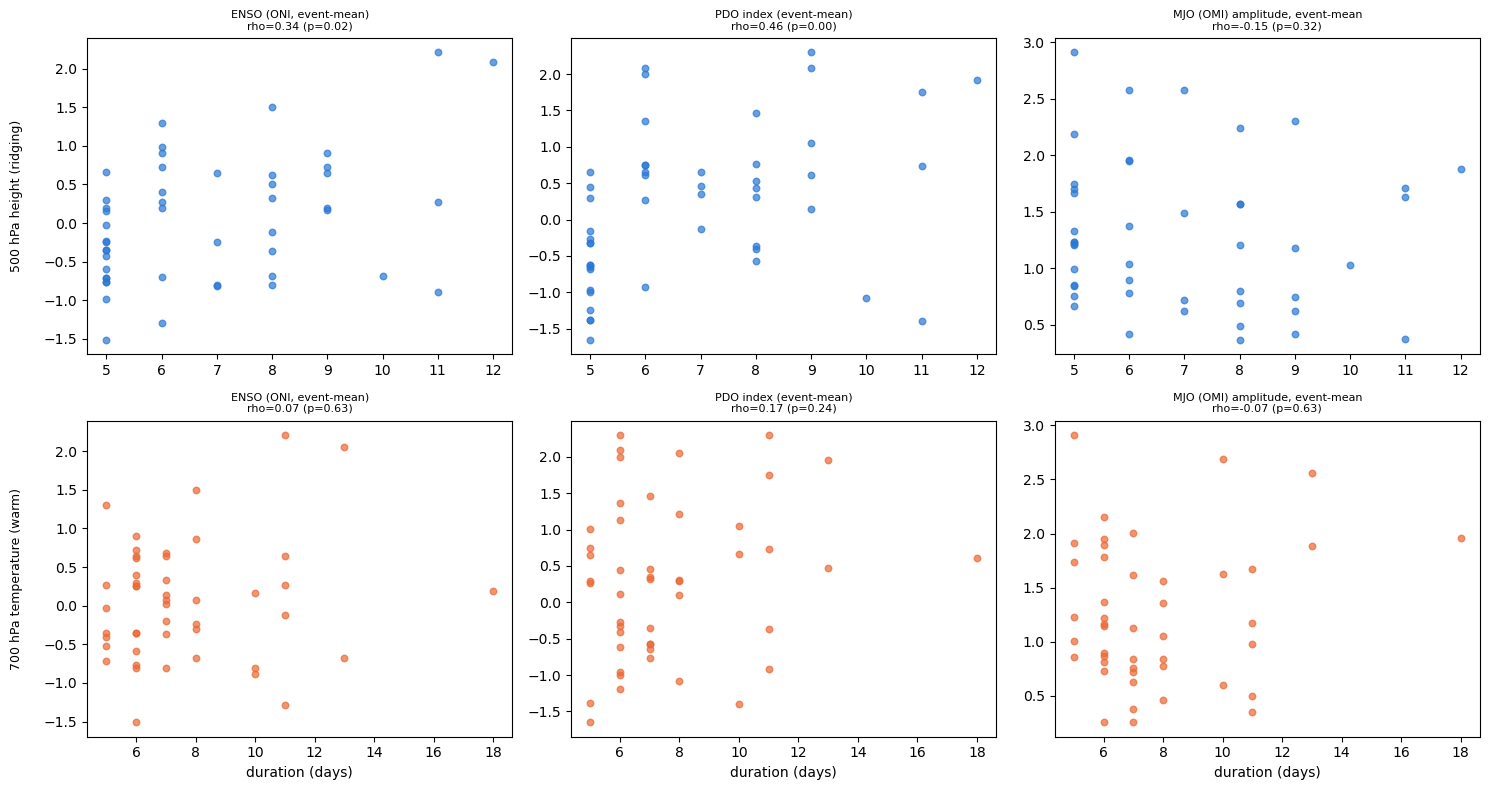

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (col, label) in enumerate(VARS):
    sub = events_full[events_full.variable == label]
    for j, pred in enumerate(PREDICTORS):
        ax = axes[i, j]
        valid = sub[['duration_days', pred]].dropna()
        ax.scatter(valid.duration_days, valid[pred], s=22, alpha=0.7, color=COLOR[label])
        r = results_df[(results_df.variable == label) & (results_df.predictor == pred)].iloc[0]
        ax.set_title(f'{PRED_LABELS[pred]}\nrho={r.rho:.2f} (p={r.p_spearman:.2f})', fontsize=8)
        if j == 0:
            ax.set_ylabel(f'{label}\n', fontsize=9)
        if i == 1:
            ax.set_xlabel('duration (days)')
plt.tight_layout()
plt.show()


## 5. Where do the WY2026 episodes -- especially March -- sit in this distribution?

Reproduces the four WY2026 Z500 episode windows exactly as the prior upstream
notebooks do (live from the frozen 1990-2025 baseline), then locates each one's own
background-state predictors within the fit-period (n=48, or n=47 for MJO since one
1990 event has no OMI data) percentile distribution. **PDO is skipped here** -- no
2026 data exists to compute it.

In [7]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in FIT_YEARS]
ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
weights = np.cos(np.deg2rad(ds.latitude))
z500 = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
df = pd.DataFrame({'z500': z500.values}, index=pd.to_datetime(ds.time.values)).sort_index()
df = df[df.index.month.isin([1, 2, 3, 4])]
sanom, diag = lib.standardize_with_trend(df.index, df['z500'].values, window=CLIM_WINDOW, label='z500', verbose=False)

ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
weights26 = np.cos(np.deg2rad(ds26.latitude))
z500_26 = ds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
df26 = pd.DataFrame({'z500': z500_26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
df26 = df26[df26.index.month.isin([1, 2, 3, 4])]
clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
df26['z500_sanom'] = (df26['z500'] - (clim_mean_arr + trend_2026)) / clim_std_arr

z500_episodes_2026 = lib.find_events(df26.index, df26['z500_sanom'].values, threshold=1,
                                      min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
z500_episodes_2026 = z500_episodes_2026[['start_date', 'end_date', 'duration_days', 'peak_sanom']].reset_index(drop=True)
z500_episodes_2026['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']

ep_rows = []
for r in z500_episodes_2026.itertuples():
    ep_rows.append({
        'enso_oni': window_mean(oni_daily, r.start_date, r.end_date),
        'mjo_amplitude_mean': window_mean(mjo_amp_daily, r.start_date, r.end_date),
        'mjo_frac_active': window_frac_active(mjo_amp_daily, r.start_date, r.end_date),
    })
z500_episodes_2026 = pd.concat([z500_episodes_2026, pd.DataFrame(ep_rows)], axis=1)
print(z500_episodes_2026[['label', 'start_date', 'end_date', 'duration_days',
                           'enso_oni', 'mjo_amplitude_mean', 'mjo_frac_active']].to_string(index=False))

z500_fit = events_full[events_full.variable == '500 hPa height (ridging)']
print('\nPercentile rank of each WY2026 episode within the fit-period (1990-2025) distribution:')
for r in z500_episodes_2026.itertuples():
    oni_pct = percentileofscore(z500_fit.enso_oni.dropna(), r.enso_oni)
    mjo_pct = percentileofscore(z500_fit.mjo_amplitude_mean.dropna(), r.mjo_amplitude_mean)
    print(f'  {r.label} ({r.duration_days}d): ENSO(ONI)={oni_pct:.0f}th pctile (ONI={r.enso_oni:.2f}), '
          f'MJO amplitude={mjo_pct:.0f}th pctile (amp={r.mjo_amplitude_mean:.2f}, '
          f'{r.mjo_frac_active*100:.0f}% of days active)')


                 label start_date   end_date  duration_days  enso_oni  mjo_amplitude_mean  mjo_frac_active
           Jan episode 2026-01-10 2026-01-18              9 -0.390000            1.402754         1.000000
  Late Jan/Feb episode 2026-01-29 2026-02-05              8 -0.277500            1.867882         0.875000
      Late Feb episode 2026-02-23 2026-03-01              7 -0.164286            1.176849         1.000000
March (record) episode 2026-03-11 2026-03-29             19  0.110000            1.016571         0.631579

Percentile rank of each WY2026 episode within the fit-period (1990-2025) distribution:
  Jan episode (9d): ENSO(ONI)=33th pctile (ONI=-0.39), MJO amplitude=62th pctile (amp=1.40, 100% of days active)
  Late Jan/Feb episode (8d): ENSO(ONI)=40th pctile (ONI=-0.28), MJO amplitude=80th pctile (amp=1.87, 88% of days active)
  Late Feb episode (7d): ENSO(ONI)=46th pctile (ONI=-0.16), MJO amplitude=47th pctile (amp=1.18, 100% of days active)
  March (record) episode 

## 6. Directly checking Davis's specific claim for March 2026

Independent of whether background state predicts duration *in general* (Section 4),
what was March 2026's own MJO and ENSO state, in plain terms?

In [8]:
march = z500_episodes_2026[z500_episodes_2026.label == 'March (record) episode'].iloc[0]
march_window = mjo_amp_daily.loc[str(march.start_date):str(march.end_date)]
march_oni = oni_daily.loc[str(march.start_date):str(march.end_date)].mean()

def enso_phase(oni):
    if oni >= 0.5:
        return 'El Nino'
    if oni <= -0.5:
        return 'La Nina'
    return 'ENSO-neutral'

print(f'March 2026 episode ({march.start_date} to {march.end_date}, {march.duration_days} days):')
print(f'  Mean OMI amplitude: {march_window.mean():.2f} (active/inactive threshold = {MJO_ACTIVE_THRESH})')
print(f'  Daily OMI amplitude range: [{march_window.min():.2f}, {march_window.max():.2f}]')
print(f'  Fraction of days >= active threshold: {(march_window >= MJO_ACTIVE_THRESH).mean()*100:.0f}%')
print(f'  Mean ONI: {march_oni:.2f} ({enso_phase(march_oni)})')


March 2026 episode (2026-03-11 to 2026-03-29, 19 days):
  Mean OMI amplitude: 1.02 (active/inactive threshold = 1.0)
  Daily OMI amplitude range: [0.91, 1.07]
  Fraction of days >= active threshold: 63%
  Mean ONI: 0.11 (ENSO-neutral)


## 7. Conclusion

**The strongest signal in the entire mechanism thread -- and the one case where a real
finding can't actually be checked against the event that started the investigation.**

- **PDO is the first Bonferroni-robust background-state result, and it's specific to
  Z500.** PDO event-mean rho=0.46 (p=0.0009, n=48) -- a *positive* (warm) PDO phase
  predicts *longer* Z500 ridging persistence. With 6 tests run here, the Bonferroni bar
  sits at p<0.0083; PDO clears it with room to spare, something no predictor in
  `CA_ridging_persistence_drivers_upstream.ipynb` or `CA_ridging_persistence_drivers_waf.ipynb`
  managed outright. T700 shows the same direction but far weaker and non-significant
  (rho=0.17, p=0.24) -- this is specifically a ridging-persistence relationship, not a
  general warm-spell one. It's also physically plausible on priors: a warm-phase PDO
  describes exactly the kind of persistent West Coast ridging pattern (e.g. the
  2013-2015 "Ridiculously Resilient Ridge") already associated with positive PDO/El
  Nino-like SST regimes in the broader literature.
- **But PDO cannot be checked against March 2026 at all -- not a null result, a data
  gap.** NOAA PSL's PDO series currently ends August 2025; there is no 2026 PDO value
  to compute, so the one relationship in this entire investigation that actually
  clears a multiple-comparisons bar is untestable for the specific event that
  motivated the whole mechanism thread. This is worth being completely explicit about:
  it is not that PDO fails to explain March, it is that the question cannot currently
  be asked.
- **ENSO (ONI) is nominally significant for Z500 but doesn't survive correction, and
  March sits dead-center.** rho=0.34 (p=0.018, n=48) -- same direction as PDO (warmer/
  El-Nino-like favors longer ridging), consistent with PDO and ENSO being correlated
  phenomena, not independent confirmations. p=0.018 does not clear the 0.0083
  Bonferroni bar. March 2026's own ONI (0.11, ENSO-neutral) sits at exactly the 50th
  percentile of the fit-period distribution -- textbook average, not an outlier in
  either direction, so even taken at face value this predictor doesn't single out
  March.
- **MJO: null relationship to duration, and Davis's specific "inactive MJO" claim for
  March doesn't hold up cleanly under this index.** Neither the continuous amplitude
  correlation (p=0.32 Z500, p=0.63 T700) nor the active/inactive Mann-Whitney split
  (p=0.67 Z500, p=0.55 T700) shows any relationship. More specifically: March 2026's
  own mean OMI amplitude was 1.02 -- right at the 1.0 active/inactive threshold, with
  daily values ranging only 0.91 to 1.07 across the whole 19-day episode and 63% of
  its days formally "active." That is a weak, borderline MJO signal, not the clearly
  inactive state the qualitative framing implied -- a direct, mild correction to the
  claim that motivated this check, independent of whether MJO state predicts duration
  in general (it doesn't).

**Net effect on the open mechanism question.** This is the first background-state
check in the thread (as opposed to instantaneous precursor fields) and it found this
project's strongest statistical result to date (PDO-Z500). But it does not resolve
March 2026: ENSO, the one predictor here that *can* be evaluated for March, places it
at dead-center; PDO, the predictor that actually matters statistically, cannot be
evaluated for March until NOAA's PDO series is updated through 2026. The honest
state of the investigation is now: a real, population-level PDO-ridging relationship
exists and deserves attention once 2026 PDO data is available, but today's picture is
still "nothing tested so far explains March specifically" -- joined, for the first
time, by "and the one thing that might, can't be checked yet."
